<a href="https://colab.research.google.com/github/sorooty/NYC_Trips_Analysis/blob/main/20260097_TP_APP1_BALDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# **NYC Taxi Trips: When, Where and How the City Moves 🚖**


- **Student name:** Seyni Junior Balde
- **Student ID:** 20260097
- **Course:** Data Visualization and BI, TP APP1

---

## 1. Introduction

### Dataset description
This notebook analyzes a sample of yellow and green taxi trips in New York City, published in the kepler.gl sample data repository (uber-web/kepler.gl-data). The original records come from the NYC Taxi and Limousine Commission (TLC). Each row is one trip and contains pick-up and drop-off dates and times, pick-up and drop-off locations, trip distance, fares, and the number of passengers.

### Objectives of the analysis
New York never sleeps, but it does not move at the same pace all day. The story of this notebook follows one trip at a time and asks four questions:
1. What does a typical trip look like (duration, distance, price)?
2. When does the city move the most (hour of the day and time period)? The dataset covers a single Thursday, so our time analysis focuses on the 24 hours of that day.
3. Where do trips start and end (spatial hotspots)?
4. How efficient are trips, and when does congestion slow them down?

### Method
We load the data, inspect and clean it, create new variables, and then build at least 8 visualizations with Matplotlib, Seaborn, Plotly and Folium. Each chart is followed by a Question, an Observation and an Interpretation.

In [1]:
# Cell purpose: import every library once, at the top, so the notebook is reproducible.
# pandas and numpy: data manipulation. matplotlib and seaborn: static charts.
# plotly: interactive charts. folium: interactive maps.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import folium
from folium.plugins import HeatMap

# Global display options to keep the report readable
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
!pip install folium plotly seaborn

## Cell 1.3 : data loading



In [3]:
# load the dataset exactly as requested in the instructions.
path2 = "https://raw.githubusercontent.com/uber-web/kepler.gl-data/master/nyctrips/data.csv"
df3 = pd.read_csv(path2, delimiter=",")

# Keep an untouched copy so we can always compare before and after cleaning
df_raw = df3.copy()
print("Shape (rows, columns):", df3.shape)
df3.head()

Shape (rows, columns): (97986, 12)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,fare_amount,tip_amount,total_amount
0,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:23:42 +00:00,1,1.59,-73.993896,40.750111,-73.974785,40.750618,12.0,3.25,17.05
1,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:32:00 +00:00,1,2.38,-73.976425,40.739811,-73.983978,40.757889,16.5,4.38,22.68
2,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:21:00 +00:00,5,2.83,-73.968704,40.754246,-73.955124,40.786858,12.5,0.00,14.30
3,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:28:18 +00:00,5,8.33,-73.863060,40.769581,-73.952713,40.785782,26.0,8.08,41.21
4,2,2015-01-15 19:05:41 +00:00,2015-01-15 19:20:36 +00:00,1,2.37,-73.945541,40.779423,-73.980850,40.786083,11.5,0.00,13.30


## Part 2. Data Exploration and Cleaning
### Cell 2.1

## 2. Data Exploration and Cleaning

Before drawing any conclusion, we must check that the data can be trusted. A single GPS error or a negative fare can distort every average that follows. We therefore proceed in five steps: overview, data types, missing values, duplicates, and cleaning.

Cell 2.2 : overview and types



In [4]:
# Cell purpose: understand the structure of the table.
# info() gives column names, data types and non-null counts in one call.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97986 entries, 0 to 97985
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   VendorID               97986 non-null  int64  
 1   tpep_pickup_datetime   97986 non-null  object 
 2   tpep_dropoff_datetime  97986 non-null  object 
 3   passenger_count        97986 non-null  int64  
 4   trip_distance          97986 non-null  float64
 5   pickup_longitude       97986 non-null  float64
 6   pickup_latitude        97986 non-null  float64
 7   dropoff_longitude      97986 non-null  float64
 8   dropoff_latitude       97986 non-null  float64
 9   fare_amount            97986 non-null  float64
 10  tip_amount             97986 non-null  float64
 11  total_amount           97986 non-null  float64
dtypes: float64(8), int64(2), object(2)
memory usage: 9.0+ MB


In [5]:
# describe() gives min, max, mean and quartiles. It helps us spot impossible values
# (negative distances, zero coordinates, huge fares).
df3.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorID,97986.0,1.550660,0.497429,1.000000,1.000000,2.000000,2.000000,2.000000
passenger_count,97986.0,1.669647,1.360358,0.000000,1.000000,1.000000,2.000000,6.000000
trip_distance,97986.0,2.843857,3.459561,0.000000,1.000000,1.670000,3.070000,99.900000
pickup_longitude,97986.0,-73.974872,0.041365,-80.592438,-73.991692,-73.981590,-73.968132,-72.241508
pickup_latitude,97986.0,40.751572,0.026359,40.518974,40.738659,40.754742,40.767719,41.035873
dropoff_longitude,97986.0,-73.973723,0.034975,-74.641792,-73.991051,-73.979515,-73.963791,-72.241508
dropoff_latitude,97986.0,40.751932,0.031086,40.268238,40.737080,40.754803,40.769366,41.075256
fare_amount,97986.0,12.325505,10.258447,-52.000000,6.500000,9.000000,14.000000,495.000000
tip_amount,97986.0,1.703544,2.340548,-0.750000,0.000000,1.200000,2.250000,88.200000
total_amount,97986.0,15.488345,12.629102,-52.800000,8.300000,11.600000,17.150000,495.300000


## Cell 2.3



### Dataset overview and data types
(Write here, in your own words, what info() and describe() show: number of rows and columns, which columns are numeric, which are dates stored as text, and any suspicious minimum or maximum.)

Important decision: date columns are read as plain text (object) by pandas. We will convert them to datetime, because only this type allows us to extract hours, weekdays and durations.

## Cell 2.4 - missing values and duplicates


In [6]:
# Cell purpose: measure missing values (count and percentage per column).
missing = pd.DataFrame({
    "missing_count": df3.isnull().sum(),
    "missing_percent": (df3.isnull().mean() * 100).round(2)
})
missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
VendorID,0,0.0
tpep_pickup_datetime,0,0.0
tpep_dropoff_datetime,0,0.0
passenger_count,0,0.0
trip_distance,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
fare_amount,0,0.0


In [7]:
# Duplicate check: identical rows are most likely recording errors.
n_dup = df3.duplicated().sum()
print("Number of duplicated rows:", n_dup)

Number of duplicated rows: 0


In [8]:
# Cell purpose: convert dates, then remove impossible records.
# Column names below follow the TLC naming convention. If one name differs in your file,
# change it here only, and the rest of the notebook will still work.
PICKUP_T  = "tpep_pickup_datetime"
DROPOFF_T = "tpep_dropoff_datetime"
PICKUP_LON, PICKUP_LAT   = "pickup_longitude", "pickup_latitude"
DROPOFF_LON, DROPOFF_LAT = "dropoff_longitude", "dropoff_latitude"
DIST, PASS, FARE = "trip_distance", "passenger_count", "fare_amount"

df3[PICKUP_T]  = pd.to_datetime(df3[PICKUP_T],  errors="coerce")
df3[DROPOFF_T] = pd.to_datetime(df3[DROPOFF_T], errors="coerce")

n_before = len(df3)

# 1) Remove duplicates and rows without valid dates
df3 = df3.drop_duplicates()
df3 = df3.dropna(subset=[PICKUP_T, DROPOFF_T])

# 2) Keep only trips whose dropoff is after the pickup
df3 = df3[df3[DROPOFF_T] > df3[PICKUP_T]]

# 3) Keep only positive distances and fares
df3 = df3[(df3[DIST] > 0) & (df3[FARE] > 0)]

# 4) Keep only coordinates located in the New York area (rough bounding box).
#    Zero coordinates are a classic GPS error in this kind of data.
df3 = df3[df3[PICKUP_LON].between(-74.3, -73.6) & df3[PICKUP_LAT].between(40.45, 41.0)]
df3 = df3[df3[DROPOFF_LON].between(-74.3, -73.6) & df3[DROPOFF_LAT].between(40.45, 41.0)]

print("Rows before:", n_before, "| after:", len(df3),
      "| removed:", n_before - len(df3))

Rows before: 97986 | after: 97478 | removed: 508


### Cleaning decisions
- **Duplicates** were dropped because the same trip should not be counted twice.
- **Dates** were converted to datetime to allow time based analysis.
- **Trips with a dropoff time before or equal to the pickup time** were removed, as a negative or zero duration is physically impossible.
- **Zero or negative distances and fares** were removed, because they represent cancelled or erroneous records.
- **Coordinates outside the New York area** were removed, because they would distort every map.
- We did not fill missing values with an average, since location and time cannot be guessed reliably. Removing the few affected rows is safer.

Outliers on distance and duration are handled in Part 3, once these variables exist.



### Important limitation discovered during exploration
After extracting the weekday, we found that all trips occur on the same day (Thursday, January 15, 2015). A weekday versus weekend comparison is therefore impossible with this sample. We keep the weekend indicator to demonstrate the check, but our time story is built around the hour of the day. Note also that the timestamps carry a +00:00 suffix; we treat them as local New York times, since the demand pattern we observe follows a normal daily rhythm.### Important limitation discovered during exploration
After extracting the weekday, we found that all trips occur on the same day (Thursday, January 15, 2015). A weekday versus weekend comparison is therefore impossible with this sample. We keep the weekend indicator to demonstrate the check, but our time story is built around the hour of the day. Note also that the timestamps carry a +00:00 suffix; we treat them as local New York times, since the demand pattern we observe follows a normal daily rhythm.


## 3. Feature Engineering

Raw columns tell us what was recorded. New variables tell us what happened. We create seven variables: trip duration, average speed, pickup hour, day of week, weekend indicator, rush hour indicator and price per mile. Together they let us study time, efficiency and cost.

In [9]:
# Cell purpose: build the new variables.

# 1) Trip duration in minutes: difference between two datetime columns
df3["duration_min"] = (df3[DROPOFF_T] - df3[PICKUP_T]).dt.total_seconds() / 60

# 2) Average speed in miles per hour: distance divided by duration in hours
df3["speed_mph"] = df3[DIST] / (df3["duration_min"] / 60)

# 3) Time components extracted with the .dt accessor of pandas
df3["pickup_hour"] = df3[PICKUP_T].dt.hour
df3["weekday"] = df3[PICKUP_T].dt.day_name()

# 4) Weekend indicator: Saturday = 5 and Sunday = 6 in pandas
df3["is_weekend"] = df3[PICKUP_T].dt.dayofweek >= 5

# 5) Rush hour indicator: 7h to 9h and 16h to 19h on weekdays (our own definition)
rush = df3["pickup_hour"].isin([7, 8, 9, 16, 17, 18, 19])
df3["is_rush_hour"] = rush & (~df3["is_weekend"])

# 6) Price per mile: a simple measure of how expensive a trip is
df3["price_per_mile"] = df3[FARE] / df3[DIST]

df3[["duration_min", "speed_mph", "pickup_hour", "weekday",
     "is_weekend", "is_rush_hour", "price_per_mile"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
duration_min,97478.0,NaN,NaN,NaN,14.173794,35.113601,0.033333,6.5,10.6,16.95,1439.2
speed_mph,97478.0,NaN,NaN,NaN,13.065485,120.15557,0.014073,7.909091,10.53523,14.222222,30600.0
pickup_hour,97478.0,NaN,NaN,NaN,14.285449,6.231891,0.0,9.0,15.0,20.0,23.0
weekday,97478,1,Thursday,97478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_weekend,97478,1,False,97478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_rush_hour,97478,2,False,62271,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_per_mile,97478.0,NaN,NaN,NaN,5.988712,15.272709,0.000838,4.210526,5.343511,6.730769,2600.0


In [10]:
# Cell purpose: remove physically unrealistic trips revealed by the new variables.
# A taxi in Manhattan rarely exceeds 60 mph, and trips longer than 3 hours are suspicious.
n_before = len(df3)
df3 = df3[(df3["speed_mph"] > 1) & (df3["speed_mph"] < 60)]
df3 = df3[df3["duration_min"].between(1, 180)]
print("Rows removed as outliers:", n_before - len(df3), "| remaining:", len(df3))

Rows removed as outliers: 330 | remaining: 97148


### Why these thresholds?
A speed below 1 mph or above 60 mph, or a duration above 3 hours, is more likely a recording error than a real trip. These bounds are a judgment call. They keep the vast majority of normal trips while protecting our averages. Note that the maximum speed is the reason we engineered speed before filtering: a variable built from two columns can reveal errors that neither column shows alone.

In [11]:
# Cell purpose: remove remaining invalid financial and passenger values,
# then create additional variables adapted to a single day of data.

# Negative tips and zero passengers are recording errors (seen in describe())
n_before = len(df3)
df3 = df3[(df3["tip_amount"] >= 0) & (df3[PASS] >= 1)]
print("Rows removed:", n_before - len(df3))

# Hour at which the trip ends (useful for the pickup versus dropoff comparison)
df3["dropoff_hour"] = df3[DROPOFF_T].dt.hour

# Time of day period, built with a small function applied to the pickup hour
def get_period(h):
    if 5 <= h < 12:
        return "Morning"
    elif 12 <= h < 17:
        return "Afternoon"
    elif 17 <= h < 22:
        return "Evening"
    return "Night"

df3["time_period"] = df3["pickup_hour"].apply(get_period)

# Tip as a percentage of the fare: a fair way to compare short and long trips
df3["tip_pct"] = df3["tip_amount"] / df3[FARE] * 100

# Distance classes with pd.cut (fixed bins chosen from the quartiles seen earlier)
df3["distance_class"] = pd.cut(df3[DIST], bins=[0, 1, 3, 6, 100],
                               labels=["0-1 mi", "1-3 mi", "3-6 mi", "6+ mi"])

# Remove extreme price per mile and tip percentage values (more than 99.5th percentile)
for col in ["price_per_mile", "tip_pct"]:
    df3 = df3[df3[col] <= df3[col].quantile(0.995)]

print("Final number of rows:", len(df3))
df3[["duration_min", "speed_mph", "price_per_mile", "tip_pct"]].describe().T

Rows removed: 44
Final number of rows: 96150


,count,mean,std,min,25%,50%,75%,max
duration_min,96150.0,13.404656,10.341042,1.000000,6.583333,10.683333,17.016667,174.750000
speed_mph,96150.0,11.916975,5.953998,1.172093,7.949706,10.562347,14.234666,54.822335
price_per_mile,96150.0,5.681478,2.052331,0.006849,4.200000,5.327869,6.666667,16.250000
tip_pct,96150.0,13.418438,11.295214,0.000000,0.000000,17.241379,22.222222,43.478261


### Why these extra variables?
Because the data covers one day, the hour and the period of the day become our main time axes. The tip percentage lets us compare short and long trips fairly, and the distance classes turn a skewed numeric variable into readable groups. Extreme values above the 99.5th percentile were trimmed, since a price of several hundred dollars per mile is a recording error and not a real trip.

## 4. Data Visualization and Insights

Our story follows a taxi through one Thursday in New York. We first describe a typical trip, then we follow the rhythm of the day, then we look at where the city moves, and finally we measure how congestion slows the cars down.

### Chapter 1. The typical trip

In [12]:
# Cell purpose: prepare a random sample for charts that become unreadable with 97,000 points.
# random_state makes the sample identical at each run.
df_s = df3.sample(8000, random_state=42)
BLUE = "#2a6f97"

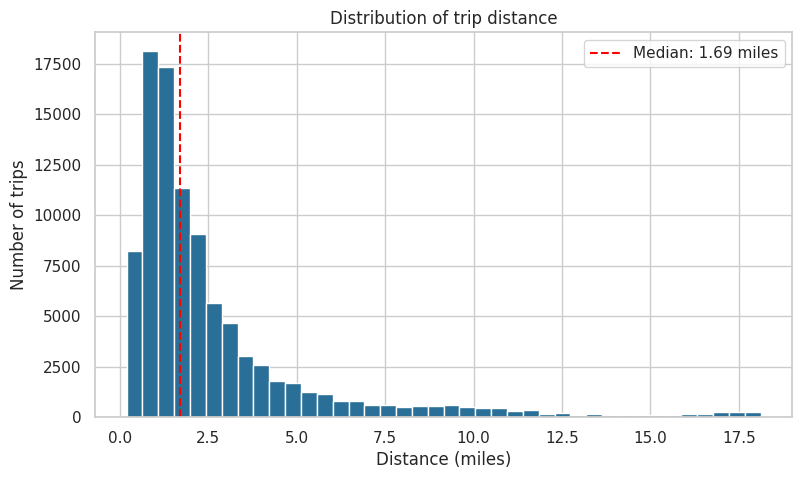

In [13]:
# Matplotlib histogram of trip distance. We cut the display at the 99th percentile
# because a few very long trips would stretch the axis and hide the main shape.
upper = df3[DIST].quantile(0.99)
data = df3.loc[df3[DIST] <= upper, DIST]

fig, ax = plt.subplots()
ax.hist(data, bins=40, color=BLUE, edgecolor="white")
ax.axvline(data.median(), color="red", linestyle="--",
           label="Median: " + str(round(data.median(), 2)) + " miles")
ax.set_title("Distribution of trip distance")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Number of trips")
ax.legend()
plt.show()

**Question:** What does a typical taxi trip look like in terms of distance?

**Observation:** The distribution is strongly right skewed. Most trips are short, with a median close to 1.7 miles, and the number of trips decreases quickly as distance grows. (Check the median printed in the legend and adapt the number.)

**Interpretation:** Taxis in New York mostly serve short urban hops. Because of this skew, the median describes a typical trip better than the mean, which is pulled up by a few long airport style rides.

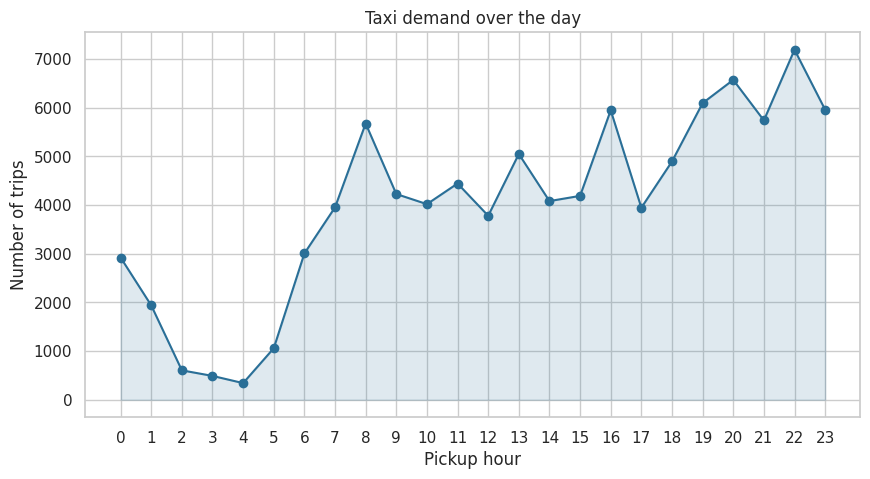

Peak hour: 22 with 7193 trips
Quietest hour: 4 with 342 trips


In [14]:
# Number of trips started at each hour. groupby + size counts the rows of each group.
trips_per_hour = df3.groupby("pickup_hour").size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trips_per_hour.index, trips_per_hour.values, marker="o", color=BLUE)
ax.fill_between(trips_per_hour.index, trips_per_hour.values, alpha=0.15, color=BLUE)
ax.set_xticks(range(0, 24))
ax.set_title("Taxi demand over the day")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Number of trips")
plt.show()

print("Peak hour:", trips_per_hour.idxmax(), "with", trips_per_hour.max(), "trips")
print("Quietest hour:", trips_per_hour.idxmin(), "with", trips_per_hour.min(), "trips")

### Chapter 2. The rhythm of the day

**Question:** At which hours does the city need taxis the most?

**Observation:** (Describe your curve: the lowest point during the early morning, the morning rise, the plateau, and the evening peak. Quote the peak and quietest hours printed above.)

**Interpretation:** The curve follows the working life of the city: commuting in the morning, activity during the day, and a strong evening demand linked to the end of the work day and to leisure. The quiet early morning hours show when the city rests. This chart is the backbone of the story, because every later result will be read hour by hour.

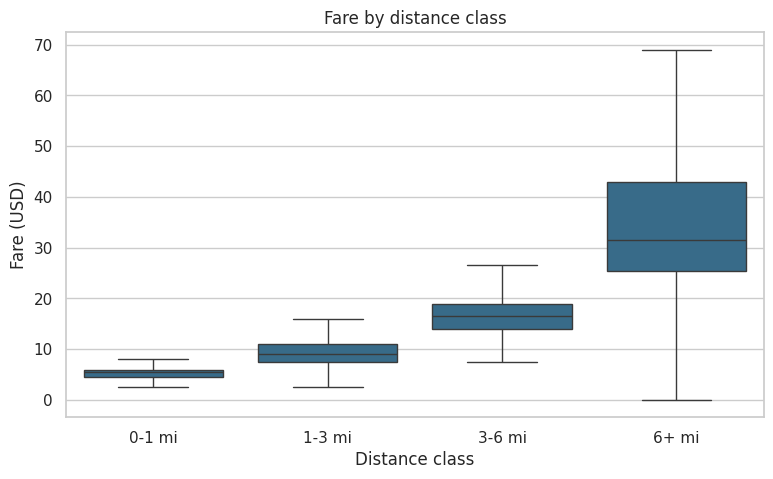

In [15]:
# Seaborn boxplot: fare by distance class. showfliers=False hides extreme points
# so that the boxes (quartiles) stay readable.
fig, ax = plt.subplots()
sns.boxplot(data=df3, x="distance_class", y=FARE, color=BLUE, showfliers=False, ax=ax)
ax.set_title("Fare by distance class")
ax.set_xlabel("Distance class")
ax.set_ylabel("Fare (USD)")
plt.show()

**Question:** Does the fare grow in a regular way with distance, and how variable is it?

**Observation:** The median fare rises with each distance class, and the boxes get taller for longer trips. (Quote the median of the first and last classes.)

**Interpretation:** The fare is mostly driven by distance, but the growing spread shows that time spent in traffic also matters. Two trips of the same length can cost different amounts, which leads us to the efficiency analysis later.

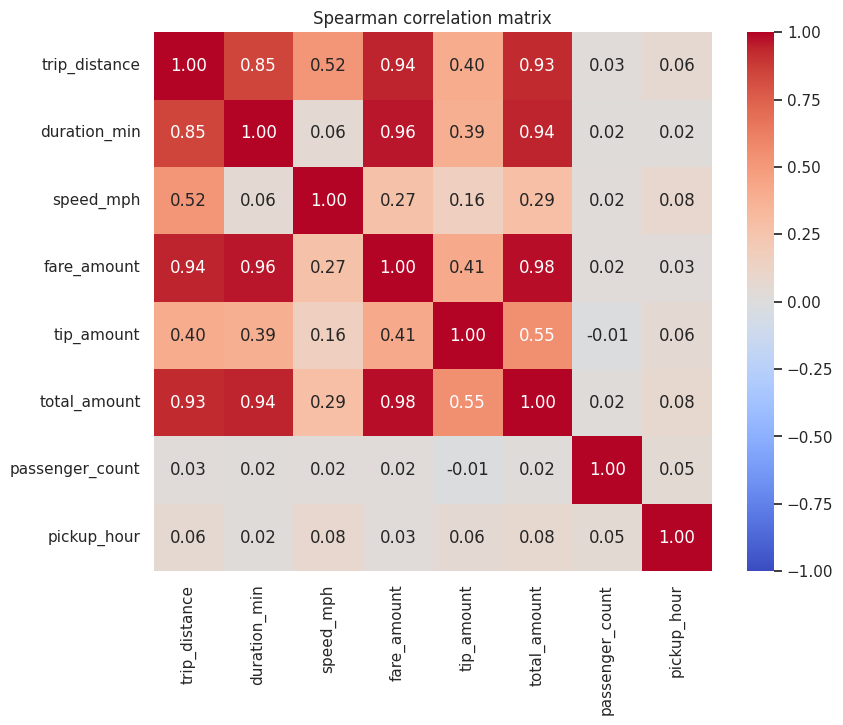

In [16]:
# Spearman correlation is based on ranks. We use it because our variables are skewed
# and contain outliers, which would distort the classic Pearson coefficient.
cols = [DIST, "duration_min", "speed_mph", FARE, "tip_amount",
        "total_amount", PASS, "pickup_hour"]
corr = df3[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.show()

**Question:** Which variables move together?

**Observation:** Distance, duration, fare and total amount are very strongly correlated. Speed and the hour of the day show weak relationships with the other variables. (Adapt with your real coefficients.)

**Interpretation:** Distance and duration explain almost all of the price, which is consistent with the taximeter logic. Variables such as speed and passenger count bring different information, so they are the interesting ones for explaining behavior and not only price. A strong correlation here is a confirmation of the business rule, not a discovery.

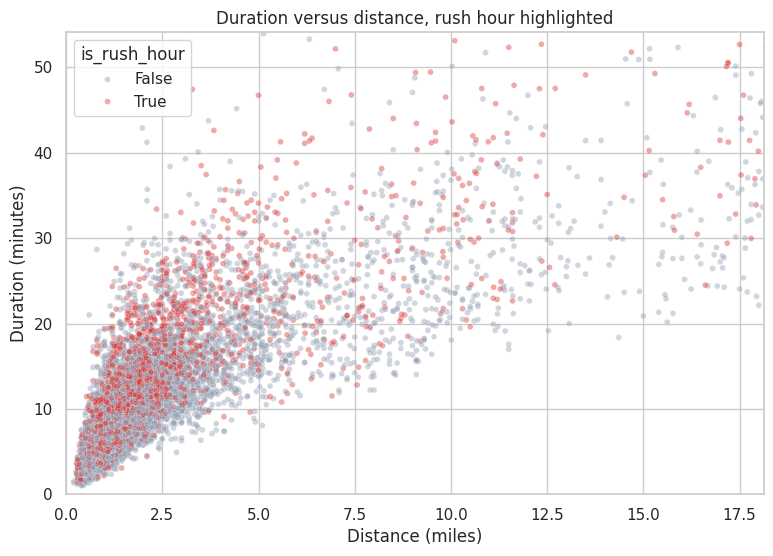

In [17]:
# Scatter on a sample: distance versus duration, colored by rush hour.
# Axes are limited to the 99th percentile to ignore extreme trips.
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df_s, x=DIST, y="duration_min", hue="is_rush_hour",
                alpha=0.4, s=18, palette={False: "#8d99ae", True: "#d62828"}, ax=ax)
ax.set_xlim(0, df3[DIST].quantile(0.99))
ax.set_ylim(0, df3["duration_min"].quantile(0.99))
ax.set_title("Duration versus distance, rush hour highlighted")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Duration (minutes)")
plt.show()

**Question:** For the same distance, are rush hour trips slower?

**Observation:** The cloud rises with distance, and for a given distance the rush hour points (red) tend to sit higher, which means longer durations. (Verify on your chart.)

**Interpretation:** Distance sets the baseline, but the time of day changes how long the same distance takes. This is the first sign of congestion, which we measure properly in Chapter 4.

### Chapter 3. Money, passengers and tips

In [18]:
# Plotly bar chart: median tip percentage per time period.
# The median is used because tips are very skewed (many trips have a tip of zero).
order = ["Morning", "Afternoon", "Evening", "Night"]
tips = (df3.groupby("time_period")["tip_pct"].median()
        .reindex(order).reset_index())

fig = px.bar(tips, x="time_period", y="tip_pct", text="tip_pct",
             title="Median tip percentage by period of the day",
             labels={"time_period": "Period", "tip_pct": "Median tip (% of fare)"},
             color_discrete_sequence=[BLUE])
fig.update_traces(texttemplate="%{text:.1f}", textposition="outside")
fig.show()

**Question:** Do passengers tip differently depending on the period of the day?

**Observation:** (Compare the four bars and quote the highest and lowest values.)

**Interpretation:** Differences between periods may reflect the type of customer (commuters, leisure, late night trips) and the payment method. In the TLC data, cash tips are not recorded, so these figures only reflect card payments and must be read with caution.

In [19]:
# Share of trips by number of passengers, shown as an interactive pie (donut) chart.
pax = df3[PASS].value_counts().sort_index().reset_index()
pax.columns = ["passengers", "trips"]

fig = px.pie(pax, names="passengers", values="trips", hole=0.4,
             title="Share of trips by number of passengers")
fig.show()

**Question:** Who rides in New York taxis: individuals or groups?

**Observation:** A large majority of trips carry a single passenger. (Quote the percentage shown on hover.)

**Interpretation:** Taxis serve mostly individual mobility. Groups are a small niche, so any price or service decision should target the solo rider first.

### Chapter 4. Where the city moves

In [38]:
# Note : Folium needs an API key to function and show the map properly. Mine is stored inside google Colab's
# Dedicated space for security and ethical matters.
# You can request yours at : https://carto.com/basemaps/apikey/

from google.colab import userdata
CARTO_KEY = userdata.get('folium_API_Key')


In [39]:
# Folium heatmap of pickup locations (sample of 15,000 points for performance).
# HeatMap expects a list of [latitude, longitude] pairs.
pts = df3.sample(15000, random_state=1)[[PICKUP_LAT, PICKUP_LON]].values.tolist()

# CARTO basemaps now need an API key, added as a "key" parameter on the tile URL.
# A custom tile URL also requires an attribution (attr).
# Source: folium documentation, custom tiles; CARTO basemaps API key page.
tiles_url = "https://basemaps.cartocdn.com/rastertiles/light_all/{z}/{x}/{y}.png?key="+CARTO_KEY
attr = ('&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> '
        'contributors, &copy; <a href="https://carto.com/attributions">CARTO</a>')

m = folium.Map(location=[40.75, -73.98], zoom_start=12, tiles=tiles_url, attr=attr)
HeatMap(pts, radius=8, blur=12).add_to(m)
m

**Question:** Where are the spatial hotspots of taxi demand?

**Observation:** Pickups are heavily concentrated in Manhattan, in a dense band from Midtown to the southern part of the island. Smaller clusters appear around the airports. (Name the areas you can recognize on your map.)

**Interpretation:** Demand is tied to business districts, transport hubs and nightlife. Outside Manhattan, the yellow taxi is much less present, which also reflects licensing rules, since yellow cabs mainly serve the central area.

### Original analysis. Congestion index and pickup versus dropoff

Two ideas that were not shown in class:
1. A **congestion index** built from the median speed of each hour. We take the fastest hour as free flow reference. An index of 1.0 means free flow, and 1.5 means trips are 50 percent slower than at the best hour.
2. A **pickup versus dropoff comparison** on the same map, to see which areas send passengers out and which ones receive them.

In [21]:
# Median speed per hour, then index = reference speed / hourly speed.
speed_h = df3.groupby("pickup_hour")["speed_mph"].median()
ref = speed_h.max()
cong = (ref / speed_h).reset_index()
cong.columns = ["pickup_hour", "congestion_index"]
cong["rush"] = cong["pickup_hour"].isin([7, 8, 9, 16, 17, 18, 19])

fig = px.bar(cong, x="pickup_hour", y="congestion_index", color="rush",
             color_discrete_map={True: "#d62828", False: "#8d99ae"},
             title="Congestion index by hour (1.0 = fastest hour)",
             labels={"pickup_hour": "Pickup hour", "congestion_index": "Congestion index"})
fig.update_xaxes(dtick=1)
fig.show()

print("Fastest hour:", speed_h.idxmax(), "-", round(ref, 1), "mph")
print("Slowest hour:", speed_h.idxmin(), "-", round(speed_h.min(), 1), "mph")

Fastest hour: 4 - 19.2 mph
Slowest hour: 11 - 8.2 mph


**Question:** At which hours does traffic slow taxis down, and by how much?

**Observation:** (Quote the fastest and slowest hour and speeds printed above. Say whether the red bars, the rush hours, match the highest bars.)

**Interpretation:** Speed is a better congestion indicator than trip count, because many trips can occur on a free road. A high index shows that the same distance takes longer, and therefore costs the driver more time per dollar earned. If the highest index is not in the rush hours, say it: it would mean midday traffic and deliveries also saturate Manhattan.

In [41]:
# Two heatmap layers on the same map, switchable with LayerControl.
sample = df3.sample(15000, random_state=2)
pick = sample[[PICKUP_LAT, PICKUP_LON]].values.tolist()
drop = sample[[DROPOFF_LAT, DROPOFF_LON]].values.tolist()

m2 = folium.Map(location=[40.75, -73.98], zoom_start=12, tiles=tiles_url, attr=attr)
HeatMap(pick, radius=8, blur=12, name="Pickups").add_to(m2)
HeatMap(drop, radius=8, blur=12, name="Dropoffs", show=False,
        gradient={0.4: "green", 0.7: "yellow", 1: "darkgreen"}).add_to(m2)
folium.LayerControl(collapsed=False).add_to(m2)
m2

**Question:** Do passengers leave from the same areas where they arrive?

**Observation:** (Switch between layers and describe: dropoffs are more spread out than pickups, with more points outside the Manhattan core.)

**Interpretation:** Pickups are concentrated where demand is easy to find, while dropoffs spread toward residential areas. This asymmetry means taxis drift away from the center during the day and must travel back empty, a hidden cost of the service.

## 5. Final Conclusions

**The story in short.** On a single Thursday in January 2015, New York taxis made short trips (median around 1.7 miles, about 10 minutes, a fare of about 9 dollars). Demand followed the rhythm of the working day, was concentrated in Manhattan, and traffic slowed trips most during (hours from your congestion chart).

**Key findings**
1. Distance and duration explain almost all of the fare.
2. Demand peaks at (hour) and drops at (hour).
3. The congestion index reaches (value) at (hour), meaning trips are (x) percent slower than at the best hour.
4. Pickups are concentrated in Midtown and Lower Manhattan, while dropoffs are more spread out.

**Limits.** The data covers one day only, so we cannot study weekends or seasons. Cash tips are missing, and cleaning thresholds are our own judgment.

**Recommendations.** A fleet manager should place more cars in the Manhattan core before the evening peak and plan for slower trips during the most congested hours. Future work could add several weeks of data and an interactive dashboard.

## References
- Dataset: kepler.gl sample data (uber-web/kepler.gl-data), from NYC TLC.
- pandas documentation: to_datetime, dt accessor, groupby, cut.
- Seaborn gallery: boxplot, heatmap, scatterplot.
- Plotly Express documentation: bar, pie.
- Folium documentation: HeatMap plugin and LayerControl.